A Deep Learning Model for the HAPT data set found at:

 https://www.kaggle.com/datasets/nickpisarevds/smartphonebased-recognition-of-hapt?resource=download

I acknowledge the use of Claude (Accessable at: Claude.ai as of November 3rd 2026) for the purposes of debugging several elements of this program in addition to providing code recommendations for how to produce the several graphical outputs which were then modified by the author.


In [45]:
#Importing libraries needed for dataset importing
import os
from google.colab import files

#Checking for access to the relevant dataset files, prompting a manual upload if not present
needed = ["X_train.txt","y_train.txt","subject_id_train.txt","X_test.txt",
          "y_test.txt","subject_id_test.txt","features.txt","activity_labels.txt"]
if not all(os.path.exists(f) for f in needed):
    files.upload()   # Note: Must select all the missing files in one upload

In [46]:
#Importing all other needed libraries for the DL model
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

#Setting a seed for more reproducible results out of random generation
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

#Setting up the variables for model training
X_train = np.loadtxt("X_train.txt", dtype=np.float32)
X_test  = np.loadtxt("X_test.txt",  dtype=np.float32)
y_train = np.loadtxt("y_train.txt", dtype=int) - 1
y_test  = np.loadtxt("y_test.txt",  dtype=int) - 1
s_train = np.loadtxt("subject_id_train.txt", dtype=int)
s_test  = np.loadtxt("subject_id_test.txt",  dtype=int)

all_names = [l.split(maxsplit=1)[1].strip() for l in open("activity_labels.txt") if l.strip()]

#Setting the activities that the model needs to recognise. Needed as the dataset includes more than these 6
TARGET_ACTIVITIES = ["WALKING", "SITTING", "STANDING", "SIT_TO_STAND", "STAND_TO_SIT"]

#Config variable. Allows the model to recognise other activities and classify them as separate from the target activities:
#      False = discard every other activity (model only ever sees the targets).
#      True  = keep them all, merged into one "OTHER" class (safer if the model will see unfamiliar movement, e.g. stairs or lying down, in real use).
ADD_OTHER_CLASS = False

#Remaps the imported data, keeping only the data for the target activities. Data for unrelated activities receive either the 'other_id' tag or the '-1' (discard) tag, depending on the config
def remap(X, y, s):
    names = [all_names[i] for i in y]
    target_idx = {n: i for i, n in enumerate(TARGET_ACTIVITIES)}
    other_id = len(TARGET_ACTIVITIES)
    new_y = np.array([target_idx.get(n, other_id if ADD_OTHER_CLASS else -1) for n in names])
    keep = new_y >= 0
    return X[keep], new_y[keep], s[keep]

#Applying the remap function on the data files
X_train, y_train, s_train = remap(X_train, y_train, s_train)
X_test,  y_test,  s_test  = remap(X_test,  y_test,  s_test)
activity_names = TARGET_ACTIVITIES + (["OTHER"] if ADD_OTHER_CLASS else [])
NUM_CLASSES = len(activity_names)

#Outputs the data for debugging purposes
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train subjects:", sorted(set(s_train)))
print("Test subjects: ", sorted(set(s_test)))

Train: (4012, 561)  Test: (1593, 561)
Train subjects: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Test subjects:  [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]


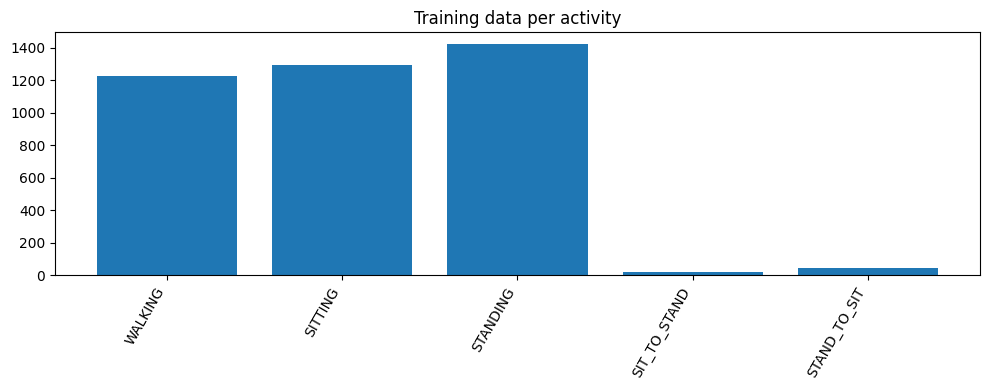

In [47]:
#Counts the amount of training data for each activity - debugging + showing why weights are needed
counts = pd.Series(y_train).value_counts().sort_index()
plt.figure(figsize=(10,4))
plt.bar([activity_names[i] for i in counts.index], counts.values)
plt.xticks(rotation=60, ha="right"); plt.title("Training data per activity"); plt.tight_layout(); plt.show()

In [48]:
#Creating a validation split from the training data for use when deciding when the model should stop. We use this to keep the test data untouched for a fairer evaluation later
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, val_idx = next(gss.split(X_train, y_train, groups=s_train))
X_tr, y_tr = X_train[tr_idx], y_train[tr_idx]
X_val, y_val = X_train[val_idx], y_train[val_idx]

#Adding weights to the classes to balance their considered importance despite the number of cases in the data (such as with the transitions between sit/stand)
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_tr)
class_weight = dict(enumerate(cw))
print("Train/val sizes:", len(X_tr), len(X_val))

Train/val sizes: 3028 984


In [49]:
#Building the model. Uses 3 main sections with dense layers that compress the features gradually, batch normalization to rescale the outputs and make the training more stable, 'relu' activation which prevents the stacked layers from collapsing into a linear model, and dropout to prevent overfitting
def build_model(n_features=561, n_classes=NUM_CLASSES):
    reg = keras.regularizers.l2(1e-4)
    m = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(512, kernel_regularizer=reg), layers.BatchNormalization(), layers.Activation("relu"), layers.Dropout(0.4),
        layers.Dense(256, kernel_regularizer=reg), layers.BatchNormalization(), layers.Activation("relu"), layers.Dropout(0.4),
        layers.Dense(128, kernel_regularizer=reg), layers.BatchNormalization(), layers.Activation("relu"), layers.Dropout(0.3),
        layers.Dense(n_classes, activation="softmax"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

model = build_model()
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 512)            │       287,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 456,197 (1.74 MB)

 Trainable params: 454,405 (1.73 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [50]:
#Callbacks tell the model when to stop training (early stopping, set to stop when the loss doesn't change over 15 epochs) and curb the learning rate for stability (halves after 5 epochs with no change)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5),
]

#Training the model, epochs are set with a max it will likely never reach, batch size updates the weights after so many data snippets
history = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                    epochs=1000, batch_size=32, class_weight=class_weight,
                    callbacks=callbacks, verbose=2)

Epoch 1/1000
95/95 - 9s - 98ms/step - accuracy: 0.7361 - loss: 1.0241 - val_accuracy: 0.4726 - val_loss: 2.1842 - learning_rate: 0.0010
Epoch 2/1000
95/95 - 0s - 5ms/step - accuracy: 0.8269 - loss: 0.6619 - val_accuracy: 0.6433 - val_loss: 1.3160 - learning_rate: 0.0010
Epoch 3/1000
95/95 - 0s - 4ms/step - accuracy: 0.8610 - loss: 0.5064 - val_accuracy: 0.7368 - val_loss: 0.5727 - learning_rate: 0.0010
Epoch 4/1000
95/95 - 1s - 7ms/step - accuracy: 0.8606 - loss: 0.5587 - val_accuracy: 0.6626 - val_loss: 1.3119 - learning_rate: 0.0010
Epoch 5/1000
95/95 - 0s - 4ms/step - accuracy: 0.8880 - loss: 0.3710 - val_accuracy: 0.8537 - val_loss: 0.4087 - learning_rate: 0.0010
Epoch 6/1000
95/95 - 0s - 4ms/step - accuracy: 0.9013 - loss: 0.3371 - val_accuracy: 0.6789 - val_loss: 0.9419 - learning_rate: 0.0010
Epoch 7/1000
95/95 - 0s - 4ms/step - accuracy: 0.9075 - loss: 0.3296 - val_accuracy: 0.9096 - val_loss: 0.3245 - learning_rate: 0.0010
Epoch 8/1000
95/95 - 0s - 4ms/step - accuracy: 0.9207 

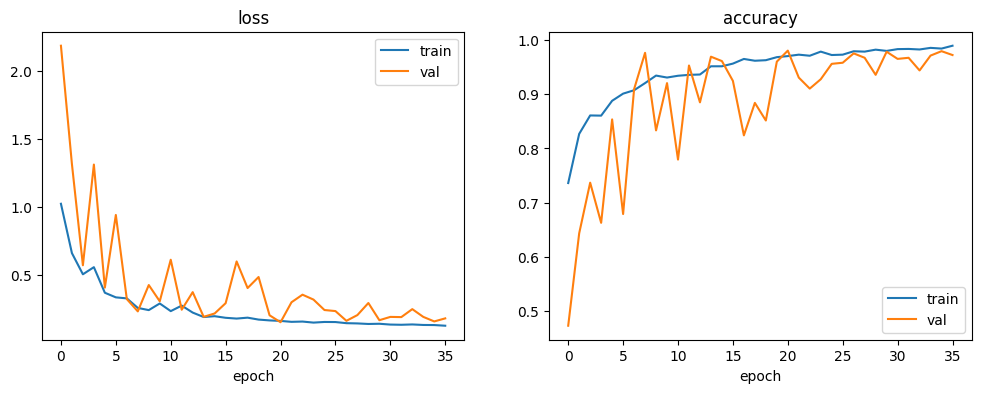

In [51]:
#Plots the loss and accuracy to show how it changes over the epochs
fig, ax = plt.subplots(1, 2, figsize=(12,4))
for a, k in zip(ax, ["loss","accuracy"]):
    a.plot(history.history[k], label="train"); a.plot(history.history["val_"+k], label="val")
    a.set_title(k); a.set_xlabel("epoch"); a.legend()
plt.show()

Test accuracy: 0.9485
              precision    recall  f1-score   support

     WALKING       1.00      1.00      1.00       496
     SITTING       0.96      0.88      0.92       508
    STANDING       0.90      0.97      0.93       556
SIT_TO_STAND       0.91      1.00      0.95        10
STAND_TO_SIT       0.88      0.91      0.89        23

    accuracy                           0.95      1593
   macro avg       0.93      0.95      0.94      1593
weighted avg       0.95      0.95      0.95      1593



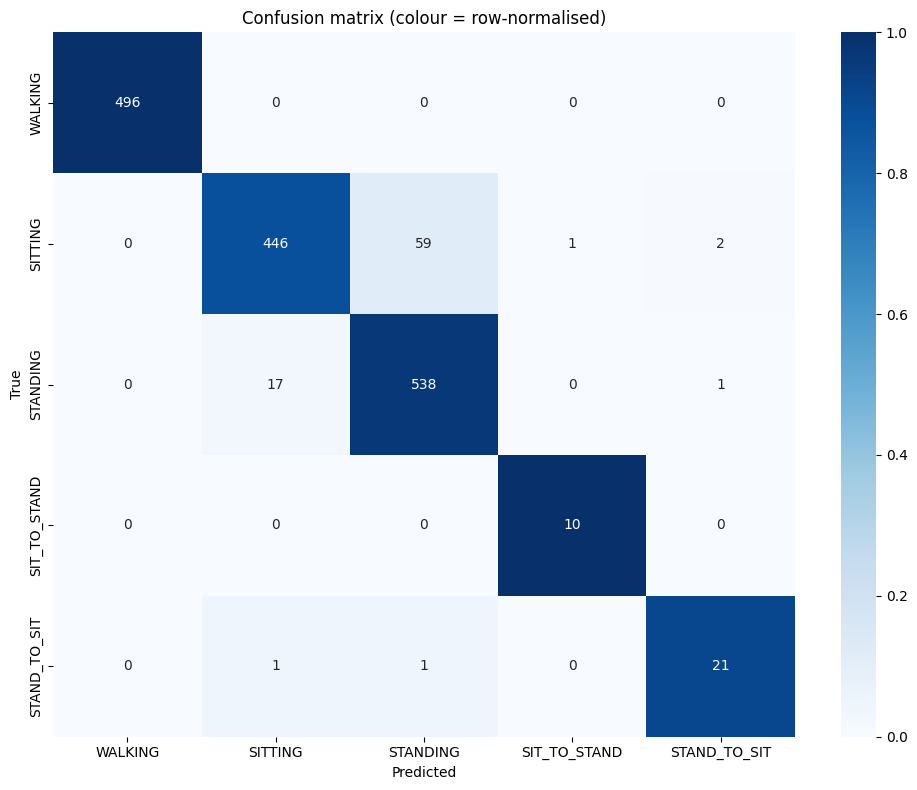

In [52]:
#Evaluation using a confusion matrix
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, y_pred, labels=range(NUM_CLASSES),
                            target_names=activity_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
plt.figure(figsize=(10,8))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues",
            xticklabels=activity_names, yticklabels=activity_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (colour = row-normalised)")
plt.tight_layout(); plt.show()